<a href="https://colab.research.google.com/github/lPragathi/GAN-PROJECT-/blob/main/CNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Dataset downloaded and extracted successfully!


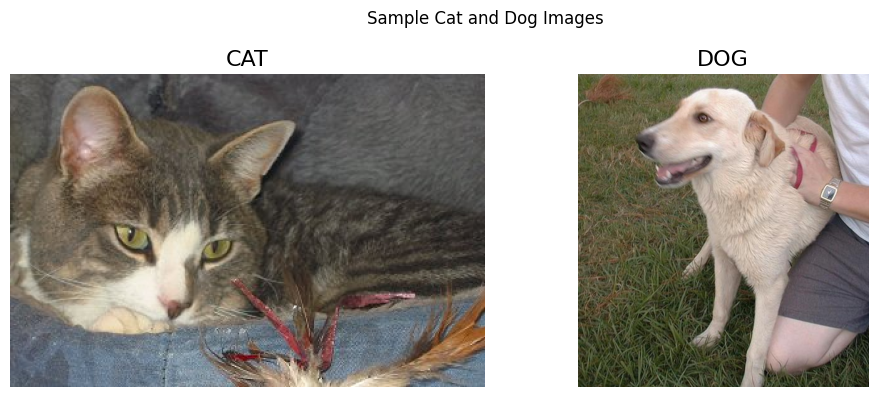

Cleaning corrupted images...
Found 23410 files belonging to 2 classes.
Using 18728 files for training.
Found 23410 files belonging to 2 classes.
Using 4682 files for validation.


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,304,769 (12.61 MB)

 Trainable params: 3,304,769 (12.61 MB)

 Non-trainable params: 0 (0.00 B)


Training CNN Model...
Epoch 1/10
586/586 ━━━━━━━━━━━━━━━━━━━━ 39s 52ms/step - accuracy: 0.5881 - loss: 0.6703 - val_accuracy: 0.6625 - val_loss: 0.6133
Epoch 2/10
586/586 ━━━━━━━━━━━━━━━━━━━━ 25s 42ms/step - accuracy: 0.6888 - loss: 0.5900 - val_accuracy: 0.7238 - val_loss: 0.5306
Epoch 3/10
586/586 ━━━━━━━━━━━━━━━━━━━━ 24s 41ms/step - accuracy: 0.7641 - loss: 0.4907 - val_accuracy: 0.7569 - val_loss: 0.4991
Epoch 4/10
586/586 ━━━━━━━━━━━━━━━━━━━━ 30s 52ms/step - accuracy: 0.8087 - loss: 0.4196 - val_accuracy: 0.8268 - val_loss: 0.4037
Epoch 5/10
586/586 ━━━━━━━━━━━━━━━━━━━━ 25s 43ms/step - accuracy: 0.8434 - loss: 0.3535 - val_accuracy: 0.8332 - val_loss: 0.3910
Epoch 6/10
586/586 ━━━━━━━━━━━━━━━━━━━━ 41s 42ms/step - accuracy: 0.8730 - loss: 0.2971 - val_accuracy: 0.8159 - val_loss: 0.4285
Epoch 7/10
586/586 ━━━━━━━━━━━━━━━━━━━━ 26s 44ms/step - accuracy: 0.8981 - loss: 0.2408 - val_accuracy: 0.8426 - val_loss: 0.3936
Epoch 8/10
586/586 ━━━━━━━━━━━━━━━━━━━━ 40s 42ms/step - accuracy: 0

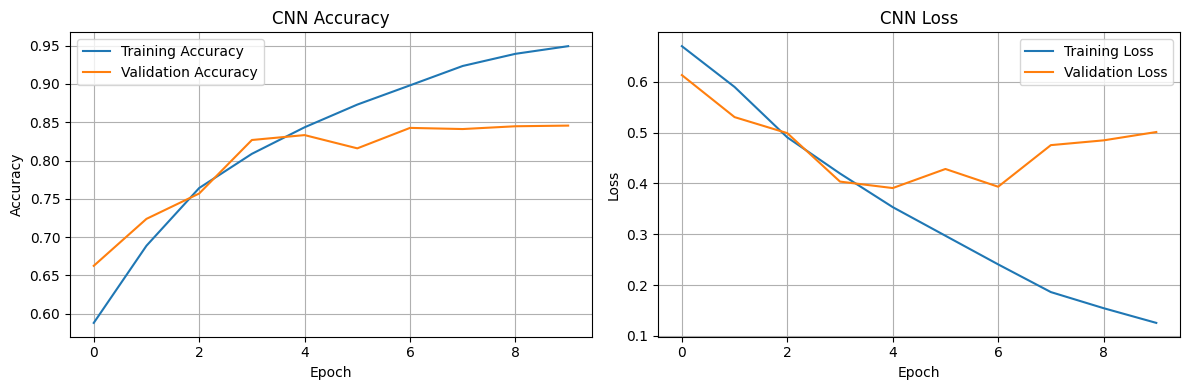

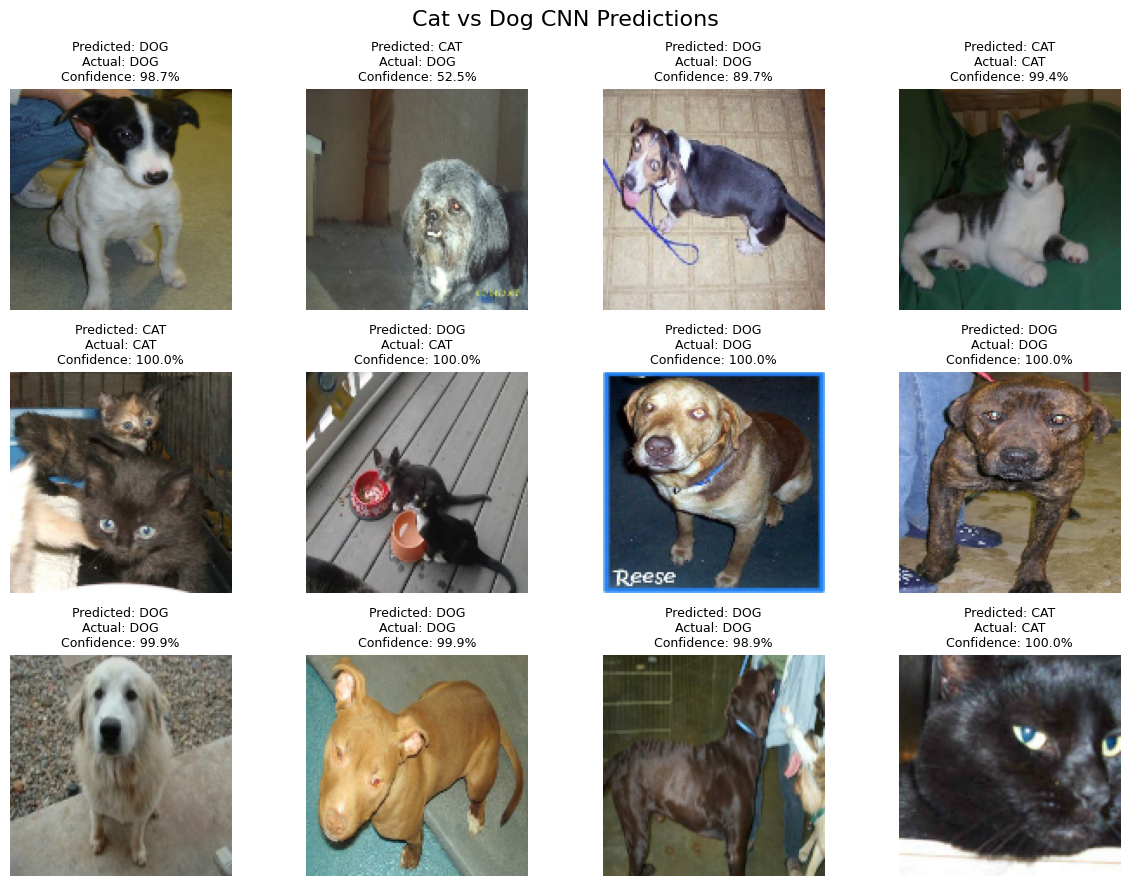


Model saved as cat_dog_cnn.keras

Upload a cat or dog image to test the model.


In [ ]:
import os
import zipfile
import random
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

from tensorflow.keras import layers, models
from google.colab import files
from PIL import Image

# 1. Download Dataset
print("Downloading Cat and Dog Dataset...")

# Using a reliable alternative mirror to avoid Google Cloud 403 blockages
url = "https://download.microsoft.com/download/3/E/1/3E1C3F21-ECDB-4869-8368-6DEBA77B919F/kagglecatsanddogs_5340.zip"
zip_path = "/content/kagglecatsanddogs.zip"

# Remove corrupted zip file if it exists
if os.path.exists(zip_path):
    os.remove(zip_path)

# Download and extract the dataset
if not os.path.exists("/content/PetImages"):
    os.system(f'curl -L "{url}" -o "{zip_path}"')
    with zipfile.ZipFile(zip_path, "r") as zip_ref:
        zip_ref.extractall("/content/")

base_dir = "/content/PetImages"
train_dir = os.path.join(base_dir, "Cat")
validation_dir = os.path.join(base_dir, "Dog")

print("Dataset downloaded and extracted successfully!")

# 2. Display Sample Cat and Dog Images
plt.figure(figsize=(10, 4))

for i, (category, folder) in enumerate([("CAT", train_dir), ("DOG", validation_dir)]):
    image_name = random.choice([f for f in os.listdir(folder) if f.endswith(".jpg")])
    image_path = os.path.join(folder, image_name)

    plt.subplot(1, 2, i + 1)
    plt.imshow(Image.open(image_path).convert("RGB"))
    plt.title(category, fontsize=16)
    plt.axis("off")

plt.suptitle("Sample Cat and Dog Images")
plt.tight_layout()
plt.show()

# Clean corrupted/non-JPEG images in the dataset before loading
print("Cleaning corrupted images...")
for folder in [train_dir, validation_dir]:
    for fname in os.listdir(folder):
        fpath = os.path.join(folder, fname)
        if fname.endswith(".jpg"):
            try:
                with open(fpath, "rb") as fobj:
                    is_jfif = tf.compat.as_bytes("JFIF") in fobj.peek(10)
                if not is_jfif:
                    os.remove(fpath)
            except Exception:
                os.remove(fpath)

# 3. Load and Prepare Dataset
IMG_SIZE = (128, 128)
BATCH_SIZE = 32
SEED = 42

# Using tf.keras.utils.image_dataset_from_directory with split to automatically divide
# Microsoft's dataset into training and validation folds
train_ds = tf.keras.utils.image_dataset_from_directory(
    base_dir,
    validation_split=0.2,
    subset="training",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    seed=SEED
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    base_dir,
    validation_split=0.2,
    subset="validation",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    seed=SEED
)

train_ds = train_ds.prefetch(tf.data.AUTOTUNE)
val_ds = val_ds.prefetch(tf.data.AUTOTUNE)

# 4. Build CNN Model
model = models.Sequential([
    layers.Input(shape=(128, 128, 3)),
    layers.Rescaling(1.0 / 255),

    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(1, activation="sigmoid")
])

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()

# 5. Train CNN
print("\nTraining CNN Model...")

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10
)

# 6. Evaluate Model
loss, accuracy = model.evaluate(val_ds, verbose=0)

print(f"\nValidation Accuracy: {accuracy * 100:.2f}%")
print(f"Validation Loss: {loss:.4f}")

# 7. Plot Accuracy and Loss
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("CNN Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("CNN Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

# 8. Display Predictions on Validation Images
class_names = ["CAT", "DOG"]

for images, labels in val_ds.take(1):
    predictions = model.predict(images, verbose=0)

    plt.figure(figsize=(12, 9))

    for i in range(min(12, len(images))):
        dog_probability = float(predictions[i][0])
        predicted_class = 1 if dog_probability >= 0.5 else 0
        actual_class = int(labels[i].numpy()[0])

        confidence = (
            dog_probability if predicted_class == 1
            else 1 - dog_probability
        ) * 100

        plt.subplot(3, 4, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(
            f"Predicted: {class_names[predicted_class]}\n"
            f"Actual: {class_names[actual_class]}\n"
            f"Confidence: {confidence:.1f}%",
            fontsize=9
        )
        plt.axis("off")

    plt.suptitle("Cat vs Dog CNN Predictions", fontsize=16)
    plt.tight_layout()
    plt.show()

# 9. Save Trained Model
model.save("/content/cat_dog_cnn.keras")
print("\nModel saved as cat_dog_cnn.keras")

# 10. Upload Your Own Image for Prediction
print("\nUpload a cat or dog image to test the model.")

uploaded = files.upload()

for filename in uploaded.keys():
    img = tf.keras.utils.load_img(
        filename,
        target_size=IMG_SIZE
    )

    img_array = tf.keras.utils.img_to_array(img)
    img_array = np.expand_dims(img_array, axis=0)

    probability = float(model.predict(img_array, verbose=0)[0][0])

    if probability >= 0.5:
        label = "DOG"
        confidence = probability * 100
    else:
        label = "CAT"
        confidence = (1 - probability) * 100

    plt.figure(figsize=(5, 5))
    plt.imshow(Image.open(filename).convert("RGB"))
    plt.title(
        f"Prediction: {label}\nConfidence: {confidence:.2f}%",
        fontsize=14
    )
    plt.axis("off")
    plt.show()

print("\nCNN Cat and Dog Classification Completed!")